# Polynomial Regression and Overfitting

- When the relationship isn't linear; Real-world data often follows **curved patterns**, not straight lines.

**Polynomial regression** allows us to model these non-linear relationships while still using the familiar tools of linear regression. 

## Challenge: The Diminishing Returns of Studying

- First few hours of studying help a lot, but eventually we hit a point where studying more actually makes things worse?
- This follows a **quadratic relationship with negative coefficient** - an inverted parabola!

Let's look at data showing this pattern: Study Hours vs. Test Scores

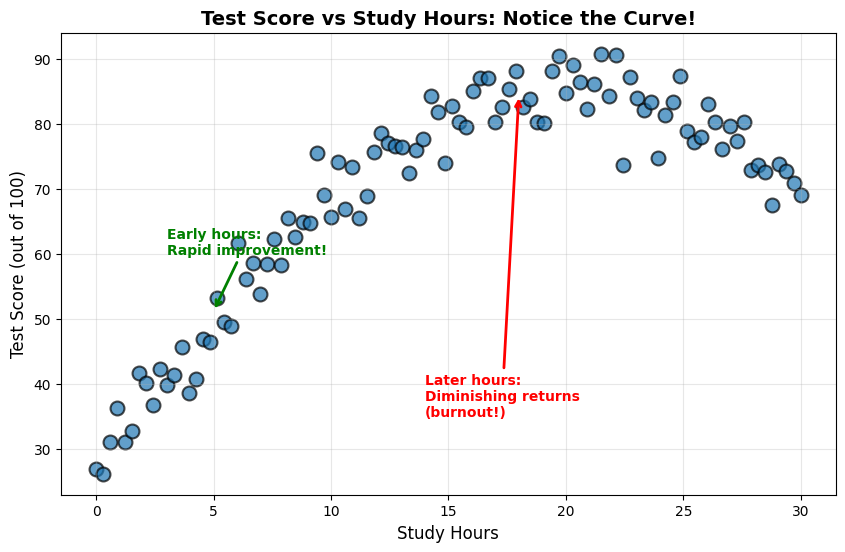

Data points: 100
Study hours range: 0 - 30 hours
Test score range: 26 - 91 points


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# Study data: Hours studied vs Test Score (out of 100)
# Generate 50 data points with clear nonlinearity
n_points = 100
study_hours = np.linspace(0, 30, n_points)

# Quadratic relationship with NEGATIVE x^2: y = a + bx - cx^2
# This creates an inverted parabola (diminishing returns that eventually decline)
base_scores = 25 + 6 * study_hours - 0.15 * study_hours**2

# Add significant noise to make it realistic
noise = np.random.normal(0, 4, n_points)  # Random variation in performance
test_scores = np.clip(base_scores + noise, 0, 100)  # Keep scores between 0-100

# Visualize the data
plt.figure(figsize=(10, 6))
plt.scatter(study_hours, test_scores, s=100, alpha=0.7, edgecolors='black', linewidth=1.5)
plt.xlabel('Study Hours', fontsize=12)
plt.ylabel('Test Score (out of 100)', fontsize=12)
plt.title('Test Score vs Study Hours: Notice the Curve!', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

# Add annotations to highlight the curve
plt.annotate('Early hours:\nRapid improvement!', 
             xy=(5, 25 + 6*5 - 0.15*5**2), xytext=(3, 60),
             arrowprops=dict(arrowstyle='->', color='green', lw=2),
             fontsize=10, color='green', fontweight='bold')
plt.annotate('Later hours:\nDiminishing returns\n(burnout!)', 
             xy=(18, 25 + 6*18 - 0.15*18**2), xytext=(14, 35),
             arrowprops=dict(arrowstyle='->', color='red', lw=2),
             fontsize=10, color='red', fontweight='bold')

plt.show()

print(f"Data points: {len(study_hours)}")
print(f"Study hours range: {study_hours.min():.0f} - {study_hours.max():.0f} hours")
print(f"Test score range: {test_scores.min():.0f} - {test_scores.max():.0f} points")

**What do you notice?**
- The points don't fall on a straight line - they follow a **curved pattern**
- The curve rises initially but then **peaks and starts to decline**
- This is a **quadratic relationship with negative x²**: y = a + bx - cx²
- Early study hours give big improvements, but too much studying leads to burnout
- A linear model would completely miss this inverted-U pattern

This is exactly where polynomial regression helps! Let's see how it can capture this curved relationship.

<img src="https://i.ibb.co/Jjs8pQ8R/poly.png" width="1000">

## <a id='toc1_'></a>[What is Polynomial Regression?](#toc0_)

Polynomial regression allows us to model non-linear relationships by transforming our input features into polynomial terms. Despite modeling curves, it remains a linear regression problem in terms of the parameters we're learning.

### <a id='toc1_1_'></a>[From Linear to Polynomial](#toc0_)

**Linear regression** assumes the relationship:

$$y = \beta_0 + \beta_1 x + \epsilon$$

**Polynomial regression** extends this to:

$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + ... + \beta_n x^n + \epsilon$$

Where:
- $y$ is the target variable
- $x$ is the input feature
- $\beta_0, \beta_1, ..., \beta_n$ are the parameters to learn
- $n$ is the degree of the polynomial
- $\epsilon$ is the error term

### <a id='toc1_2_'></a>[Still Linear in Parameters](#toc0_)

An important insight: polynomial regression is **linear in parameters** even though it models non-linear relationships.

Consider: $y = \beta_0 + \beta_1 x + \beta_2 x^2$

If we create new features:
- $x_1 = x$
- $x_2 = x^2$

The equation becomes: $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2$

This is standard multiple linear regression! We:
1. **Transform** the features non-linearly ($x \rightarrow x, x^2, x^3, ...$)
2. **Apply** linear regression on the transformed features
3. **Use** all the same techniques: normal equation, gradient descent, etc.

**Using the OLS Formula:**

Since polynomial regression is linear in parameters, we can use the exact same Ordinary Least Squares (OLS) formula we learned for linear regression:

$$\beta = (X^T X)^{-1} X^T y$$

Where:
- $X$ is our design matrix containing the polynomial features $[x, x^2, x^3, ..., x^d]$
- $\beta$ contains our parameters $[\beta_0, \beta_1, \beta_2, ..., \beta_d]$
- $y$ is our target variable

The beauty is that the **same closed-form solution** works for polynomial regression! We just need to:
1. Create polynomial features from our original $x$ values
2. Add the intercept column (all ones) to the design matrix
3. Apply the OLS formula

This means all the mathematical machinery we developed for linear regression carries over directly to polynomial regression.

## <a id='toc2_'></a>[Implementing Polynomial Regression](#toc0_)

### <a id='toc1_2_'></a>[Still Linear in Parameters](#toc0_)

- Now that we understand the theory, let's implement polynomial regression using scikit-learn, which we introduced in the linear regression notebook.
- We'll use sklearn's `PolynomialFeatures` to transform our features and `LinearRegression` to fit the model.

Scikit-learn makes feature transformation easy with the `PolynomialFeatures` class:

In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Create a PolynomialFeatures transformer
poly = PolynomialFeatures(degree=3, include_bias=False)

# Example: Transform a simple array
X_sample = np.array([[1], [2], [3], [4], [5]])
X_poly_sample = poly.fit_transform(X_sample)

print("Original X:")
print(X_sample.flatten())
print("\nPolynomial features (degree 3):")
print(X_poly_sample)
print("\nShape:", X_poly_sample.shape)
print("\nFeature names:", poly.get_feature_names_out())

Original X:
[1 2 3 4 5]

Polynomial features (degree 3):
[[  1.   1.   1.]
 [  2.   4.   8.]
 [  3.   9.  27.]
 [  4.  16.  64.]
 [  5.  25. 125.]]

Shape: (5, 3)

Feature names: ['x0' 'x0^2' 'x0^3']


Notice how sklearn automatically creates polynomial features for us! Each column represents a power of $x$: the first column is $x^1$, second is $x^2$, third is $x^3$.

**Key sklearn parameters:**
- `degree`: The polynomial degree
- `include_bias=False`: We don't want sklearn to add the intercept column (LinearRegression will handle that)

Once we have polynomial features, we can use sklearn's `LinearRegression` (just like we learned before!):

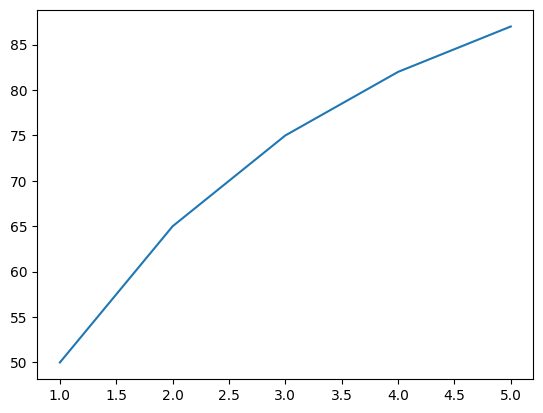

In [4]:
# Simpler presentation; suppose our dataset is
hours = np.array([1, 2, 3, 4, 5])
scores = np.array([50, 65, 75, 82, 87])

plt.plot(hours, scores)

Learned parameters for test scores vs study hours:
Beta 0 (intercept): 24.79
Beta 1 (hours): 5.9207
Beta 2 (hours^2): -0.14674212

Notice the negative beta_2 - this captures the diminishing returns!


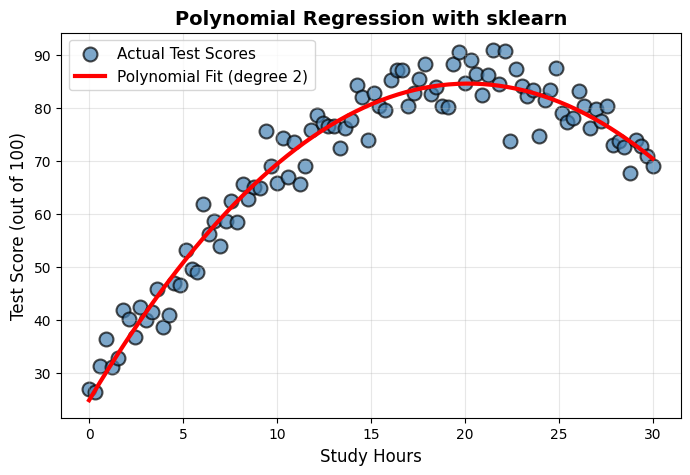

In [ ]:
# Use our study hours dataset
X_train = study_hours.reshape(-1, 1)
y_train = test_scores

# Create polynomial features (degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_train)

# fit_transform
# creates additional polynomial features; convert study-hours value into x and x^2
# Allow linear regression to learn curved relationship rather than a straight line.

# Fit linear regression on polynomial features
model = LinearRegression()
model.fit(X_poly, y_train)
# .fit(X_poly, y_train) finds the coefficients that best explain the relationship
# between the polynomial features and the actual test scores.

print("Learned parameters for test scores vs study hours:")
print(f"Beta 0 (intercept): {model.intercept_:.2f}")
print(f"Beta 1 (hours): {model.coef_[0]:.4f}")
print(f"Beta 2 (hours^2): {model.coef_[1]:.8f}")
print("\nNotice the negative beta_2 - this captures the diminishing returns!")

# Generate smooth curve for plotting
X_plot = np.linspace(study_hours.min(), study_hours.max(), 200).reshape(-1, 1)
X_plot_poly = poly.transform(X_plot)
y_pred = model.predict(X_plot_poly)

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, s=100, alpha=0.7, edgecolors='black', linewidths=1.5, 
            label='Actual Test Scores', color='steelblue')
plt.plot(X_plot, y_pred, 'r-', linewidth=3, label='Polynomial Fit (degree 2)')
plt.xlabel('Study Hours', fontsize=12)
plt.ylabel('Test Score (out of 100)', fontsize=12)
plt.title('Polynomial Regression with sklearn', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()

**Interpreting the Coefficients:**

Our model learned a quadratic relationship from the data.

The equation will be something like: 

**Test Score = β₀ + β₁×(hours) + β₂×(hours²)**

Where:
- **β₀**: Baseline test score with zero study hours
- **β₁**: Linear coefficient -> positive, showing initial benefit of studying
- **β₂**: Quadratic coefficient -> **negative** value captures diminishing returns and eventual decline (burnout effect!)

This captures the realistic pattern where studying helps initially, but excessive studying beyond a certain point leads to fatigue and worse performance!

Once we have polynomial features, we can use OLS to find optimal parameters.

### <a id='toc2_3_'></a>[Comparing Different Degrees](#toc0_)

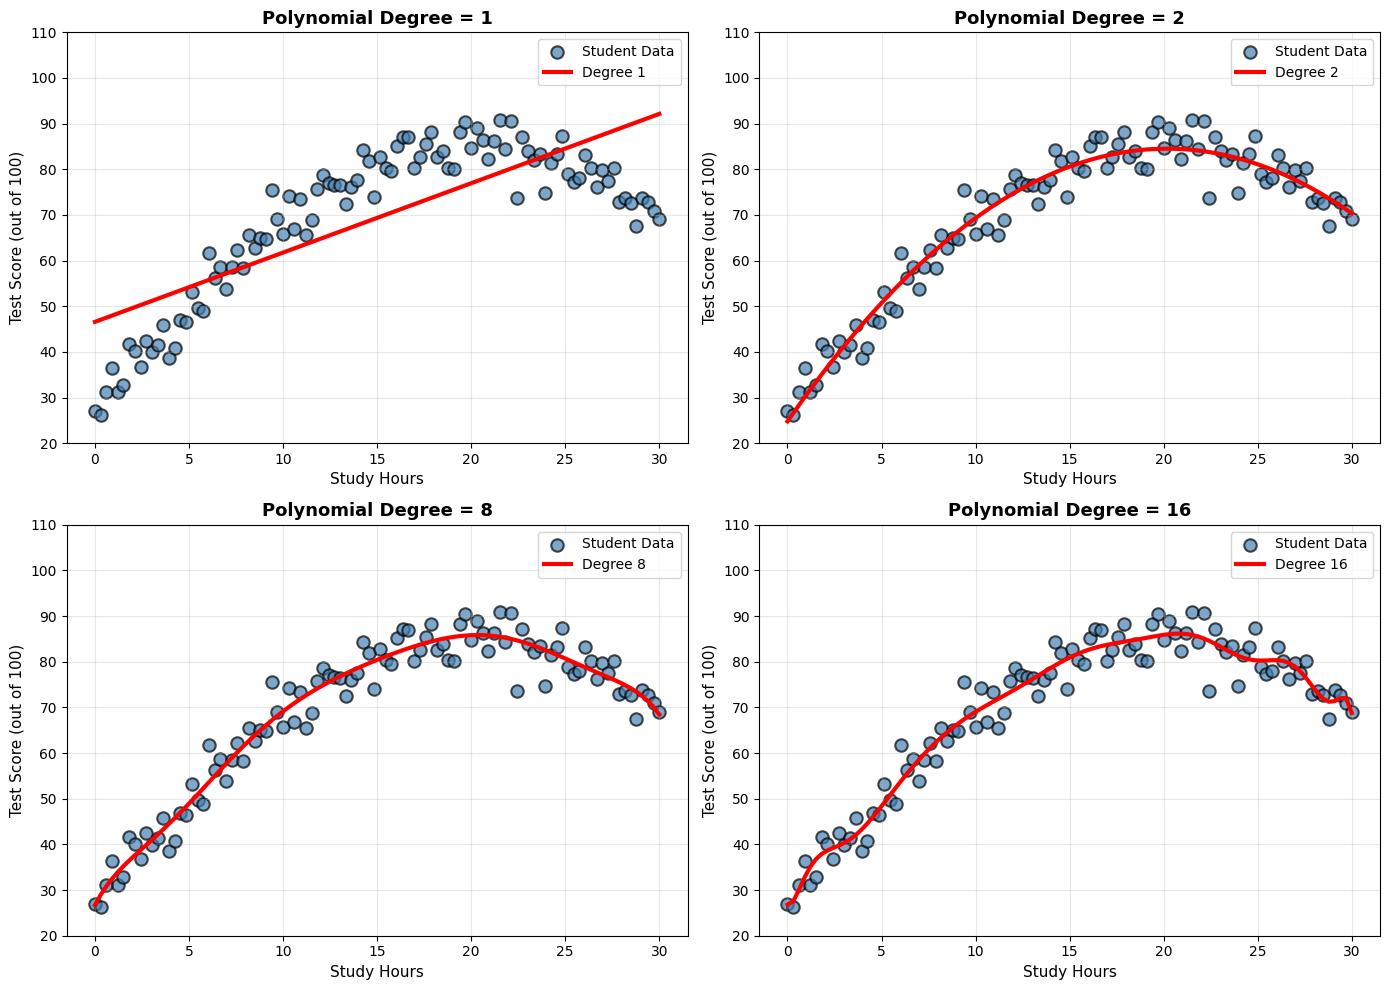

In [23]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Use our study hours data
X = study_hours.reshape(-1, 1)
y = test_scores.reshape(-1, 1)

# Manual normalization (standardization)
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_normalized = (X - X_mean) / X_std

# Try different polynomial degrees
degrees = [1, 2, 8, 16]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, degree in enumerate(degrees):
    # Create polynomial features
	poly = PolynomialFeatures(degree=degree)
	X_poly = poly.fit_transform(X_normalized)

	# Fit model using sklearn
	model = LinearRegression()
	model.fit(X_poly, y)
	y_pred = model.predict(X_poly)  # Predict on training data itself

	# Plot
	axes[idx].scatter(X, 
						y, 
						alpha=0.7, 
						s=80, 
						edgecolors='black', 
						linewidths=1.5,
						label='Student Data', 
						color='steelblue')

	axes[idx].plot(X, y_pred, 'r-', linewidth=3, label=f'Degree {degree}')

	axes[idx].set_xlabel('Study Hours', fontsize=11)
	axes[idx].set_ylabel('Test Score (out of 100)', fontsize=11)
	axes[idx].set_title(f'Polynomial Degree = {degree}', fontsize=13, fontweight='bold')
	axes[idx].legend(fontsize=10)
	axes[idx].grid(True, alpha=0.3)
	axes[idx].set_ylim([20, 110])

plt.tight_layout()
plt.show()

#### The Lesson
More complexity ≠ better model. The degree 2 polynomial strikes the perfect balance: sophisticated enough to capture the real pattern, simple enough to generalize to new data.

### <a id='toc2_4_'></a>[The Fundamental Question: How Do We Choose the Right Degree?](#toc0_)

Looking at our polynomial regression examples, a critical question emerges: **How do we know which degree to use?**

We saw that:
- Degree 1: Too simple
- Degree 2: Looks good
- Degree 8: Getting wiggly
- Degree 16: Completely crazy

But how do we make this decision **systematically** rather than just eyeballing graphs?

#### **The Naive Approach (That Doesn't Work)**

You might think: "Let's just calculate the error on our training data and pick the degree with the lowest error!"

**The problem:** Higher degrees will ALWAYS have lower training error!
- Degree 16 will fit the training data nearly perfectly
- But it will fail miserably on new students
- **Training error is a terrible judge of model quality**

#### **What We Really Care About**

We don't care how well the model fits the training data. We care about:
> **"How well will this model perform on students it has NEVER seen before?"**

This is called **generalization** - the ability to make good predictions on new, unseen data.

#### **The Solution: Hold Out a Validation Set**

The key insight: We need to **simulate** what happens with new data BEFORE we deploy the model.

**The strategy:**
1. **Training Set (60%)**: Used to fit the model parameters (θ)
2. **Validation Set (20%)**: Used to evaluate different models and choose hyperparameters (like degree)
3. **Test Set (20%)**: Final evaluation of the chosen model (touched only once!)

#### How it works?

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Step 1: Split the data (60% train, 20% validation, 20% test)
# First split: 60% train, 40% temp
X_train, X_temp, y_train, y_temp = train_test_split(study_hours.reshape(-1, 1),
													test_scores, 
													test_size=0.4,
													random_state=42)

# Second split: Split the 40% into half validation and half test
X_val, X_test, y_val, y_test = train_test_split(X_temp,
												y_temp, 
												test_size=0.5,
												random_state=42)

print(f"Dataset sizes:")
print(f"Training: {len(X_train)} students")
print(f"Validation: {len(X_val)} students")
print(f"Test: {len(X_test)} students")
print(f"Total: {len(X_train) + len(X_val) + len(X_test)} students\n")

# Normalize the data (using training statistics)
X_mean = np.mean(X_train)
X_std = np.std(X_train)

X_train_norm = (X_train - X_mean) / X_std
X_val_norm = (X_val - X_mean) / X_std
X_test_norm = (X_test - X_mean) / X_std

# Step 2: Try different degrees and evaluate on VALIDATION set
degrees_to_try = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16]
train_errors = []
val_errors = []

print("Evaluating different polynomial degrees:")
print("-" * 60)

for degree in degrees_to_try:
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train_norm)
    X_val_poly = poly.transform(X_val_norm)
    
    # Fit model
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    # Evaluate on both training and validation
    y_train_pred = model.predict(X_train_poly)
    y_val_pred = model.predict(X_val_poly)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    val_mse = mean_squared_error(y_val, y_val_pred)
    
    train_errors.append(train_mse)
    val_errors.append(val_mse)
    
    print(f"Degree {degree:2d} | Train MSE: {train_mse:6.2f} | Val MSE: {val_mse:6.2f}")

# Step 3: Pick the degree with lowest validation error
best_degree = degrees_to_try[np.argmin(val_errors)]
best_val_error = min(val_errors)

print("\n" + "=" * 60)
print(f"🎯 BEST DEGREE: {best_degree} (Validation MSE: {best_val_error:.2f})")
print("=" * 60)

# Step 4: Train final model on train set and evaluate ONCE on test set
poly_final = PolynomialFeatures(degree=best_degree)
X_train_poly_final = poly_final.fit_transform(X_train_norm)
X_test_poly_final = poly_final.transform(X_test_norm)

final_model = LinearRegression()
final_model.fit(X_train_poly_final, y_train)

y_test_pred = final_model.predict(X_test_poly_final)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"\n✅ Final Test Set Performance (degree {best_degree}): MSE = {test_mse:.2f}")
print(f"   (This is our honest estimate of real-world performance!)")

Dataset sizes:
Training: 60 students
Validation: 20 students
Test: 20 students
Total: 100 students

Evaluating different polynomial degrees:
------------------------------------------------------------
Degree  1 | Train MSE: 118.10 | Val MSE:  89.31
Degree  2 | Train MSE:  15.44 | Val MSE:   5.53
Degree  3 | Train MSE:  14.72 | Val MSE:   4.63
Degree  4 | Train MSE:  14.69 | Val MSE:   4.32
Degree  5 | Train MSE:  14.61 | Val MSE:   4.69
Degree  6 | Train MSE:  14.60 | Val MSE:   4.81
Degree  8 | Train MSE:  14.32 | Val MSE:   5.41
Degree 10 | Train MSE:  12.56 | Val MSE:   9.60
Degree 12 | Train MSE:  12.23 | Val MSE:  10.77
Degree 16 | Train MSE:  10.86 | Val MSE:  21.04

🎯 BEST DEGREE: 4 (Validation MSE: 4.32)

✅ Final Test Set Performance (degree 4): MSE = 13.65
   (This is our honest estimate of real-world performance!)


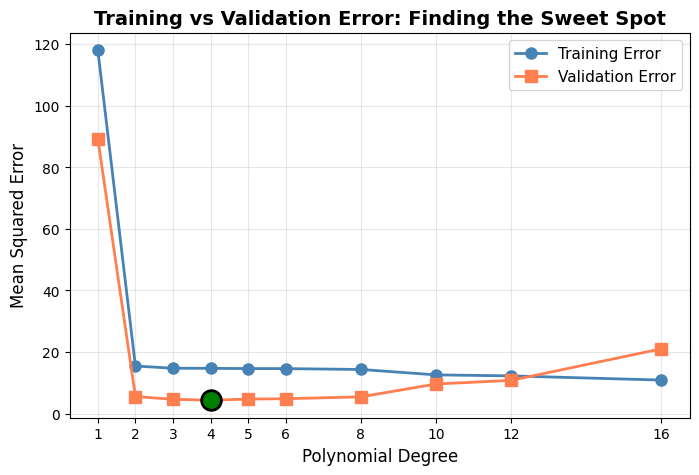

In [25]:
# Visualize training vs validation error
plt.figure(figsize=(8, 5))
plt.plot(degrees_to_try, train_errors, 'o-', linewidth=2, markersize=8, 
         label='Training Error', color='steelblue')
plt.plot(degrees_to_try, val_errors, 's-', linewidth=2, markersize=8, 
         label='Validation Error', color='coral')

# Mark the best degree
plt.scatter([best_degree], [best_val_error], color='green', s=200, zorder=5, 
            edgecolors='black', linewidths=2)

plt.xlabel('Polynomial Degree', fontsize=12)
plt.ylabel('Mean Squared Error', fontsize=12)
plt.title('Training vs Validation Error: Finding the Sweet Spot', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xticks(degrees_to_try)

plt.show()

#### **What We Just Discovered**

Through systematic validation, we found that:

1. **Training error alone is misleading**:
   - Degree 16 had the lowest training error
   - But it performed terribly on validation data
   - It memorized noise instead of learning patterns

2. **Validation reveals generalization**:
   - The validation set simulates "unseen" data
   - It showed us that degree 2-3 generalizes best
   - Higher degrees overfit, lower degrees underfit

**The bottom line**: This validation approach is how we make principled model selection decisions in machine learning!

## <a id='toc3_'></a>[Understanding Overfitting and Underfitting](#toc0_)

### <a id='toc3_1_'></a>[The Goldilocks Problem: Finding the Right Complexity](#toc0_)

When training machine learning models, we face a fundamental challenge: finding the **right level of complexity**. Too simple is bad, too complex is bad. We need it *just right*.


### **Underfitting: Too Simple**

**What is it?**  
The model is too simplistic to capture the actual patterns in the data. It's like trying to describe a curved road using only straight lines.

**Symptoms:**
- ❌ Poor performance on training data
- ❌ Poor performance on new, unseen data
- The model misses important patterns and relationships
- Predictions are consistently off the mark

**Example:**  
Using a straight line (degree 1) to model the study hours → test score relationship. It assumes a constant rate of improvement, completely missing the inverted-U pattern where too much studying hurts performance.

**Why it happens:**
- Model is too simple for the problem
- Not enough features or flexibility
- Overly restrictive assumptions


### **Overfitting: Too Complex**

**What is it?**  
The model learns the training data *too well*, including random noise and quirks specific to that dataset. It **memorizes** rather than **generalizes**.

**Symptoms:**
- ✅ Excellent (sometimes perfect) performance on training data
- ❌ Poor performance on new, unseen data
- The model fits every tiny fluctuation in training data
- Unrealistic wiggles and oscillations in predictions

**Example:**  
Using a degree 16 polynomial for study hours → test scores. It perfectly hits every training point but makes wild, unrealistic predictions between them.

**Why it happens:**
- Model is too complex for the amount of data
- Too many parameters/features
- Training for too long
- Not enough training examples


### **The Sweet Spot: Just Right**

The ideal model:
- ✅ Good performance on training data (not perfect)
- ✅ Good performance on new, unseen data
- Captures real patterns, ignores noise
- Makes sensible predictions

**Example:**  
A degree 4 polynomial that captures the inverted-U pattern (diminishing returns and burnout) without chasing every random fluctuation.

In [26]:
# zip
comparison_degrees = [1, 2, 3]
titles = ["Linear", "Quadratic", "Cubic"]
colors = ["red", "green", "blue"]

a = zip(comparison_degrees, titles, colors)
list(a)

[(1, 'Linear', 'red'), (2, 'Quadratic', 'green'), (3, 'Cubic', 'blue')]

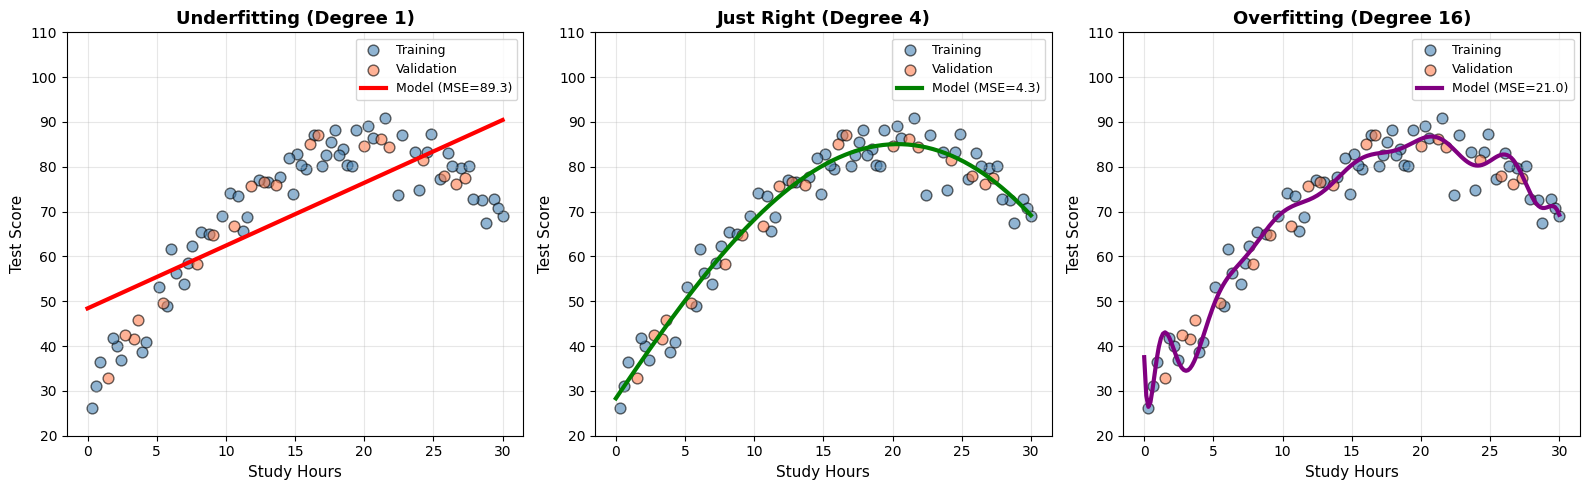


📊 Visual Confirmation:
• Degree 1: Too simple - Underfitting
• Degree 4: Perfect - captures the pattern, generalizes well
• Degree 16: Too complex - Overfitting


In [27]:
# Compare the best model with underfitting and overfitting
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Prepare plot data
X_plot = np.linspace(study_hours.min(), study_hours.max(), 200).reshape(-1, 1)
X_plot_norm = (X_plot - X_mean) / X_std

comparison_degrees = [1, best_degree, 16]
titles = ['Underfitting (Degree 1)', f'Just Right (Degree {best_degree})', 'Overfitting (Degree 16)']
colors = ['red', 'green', 'purple']

for idx, (degree, title, color) in enumerate(zip(comparison_degrees, titles, colors)):
    # Fit model
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train_norm)
    X_plot_poly = poly.transform(X_plot_norm)
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_plot = model.predict(X_plot_poly)
    
    # Calculate errors
    X_val_poly = poly.transform(X_val_norm)
    y_val_pred = model.predict(X_val_poly)
    val_mse = mean_squared_error(y_val, y_val_pred)
    
    # Plot
    axes[idx].scatter(X_train, y_train, alpha=0.6, s=60, label='Training', 
                     edgecolors='black', linewidths=1, color='steelblue')
    axes[idx].scatter(X_val, y_val, alpha=0.6, s=60, label='Validation', 
                     edgecolors='black', linewidths=1, color='coral')
    axes[idx].plot(X_plot, y_plot, linewidth=3, color=color, label=f'Model (MSE={val_mse:.1f})')
    
    axes[idx].set_xlabel('Study Hours', fontsize=11)
    axes[idx].set_ylabel('Test Score', fontsize=11)
    axes[idx].set_title(title, fontsize=13, fontweight='bold')
    axes[idx].legend(fontsize=9)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([20, 110])

plt.tight_layout()
plt.show()

print(f"\n📊 Visual Confirmation:")
print(f"• Degree 1: Too simple - Underfitting")
print(f"• Degree {best_degree}: Perfect - captures the pattern, generalizes well")
print(f"• Degree 16: Too complex - Overfitting")

### <a id='toc3_2_'></a>[Detecting Underfitting and Overfitting: The Key Diagnostic](#toc0_)


The core idea: **Compare training error and validation error.**

* **Training error** always decreases as model complexity increases.
* **Validation error** forms a **U-shape**: decreases, hits a minimum, then rises again.

#### Zones

| Region                 | Training Error | Validation Error | Gap            | Interpretation                           |
| ---------------------- | -------------- | ---------------- | -------------- | ---------------------------------------- |
| **Low Complexity**     | High           | High             | Small          | **Underfitting** (model is too simple)   |
| **Optimal Complexity** | Moderate       | **Lowest**       | Small/Moderate | **Good generalization**                  |
| **High Complexity**    | Very Low       | High             | **Large**      | **Overfitting** (model memorizing noise) |

#### Key Signal

* **Small gap** → generalizes well
* **Large gap** → overfitting

That's the whole diagnostic:
**Watch the validation curve and the gap between training and validation error.**

<img src="./assets/complexity-error.png" width="800">

### <a id='toc3_3_'></a>[Why Overfitting is the Bigger Concern](#toc0_)

While both underfitting and overfitting are problems, **overfitting tends to be the more critical challenge** in machine learning practice. Here's why:

#### **Harder to Detect**
- **Underfitting:** Training accuracy is 60%? Obviously problematic.
- **Overfitting:** Training accuracy is 99%, test accuracy is 65%? The gap reveals the issue, but it's subtle.

**Underfitting?** Obvious immediately - even training performance is bad.

#### **Modern Models are Big**
- Today's ML models can have billions of parameters
- **Default tendency:** Complex models naturally drift toward overfitting if unchecked

**Underfitting?** Less common with modern powerful models.

## <a id='toc4_'></a>[Best Practices](#toc0_)

When working with polynomial regression and dealing with overfitting, follow these principles:

#### **1. Always Use a Validation Set**
- Never choose model complexity based on training error alone
- Split data: 60% train, 20% validation, 20% test
- Use validation set to compare different polynomial degrees
- Touch test set only once at the very end

#### **2. Start Simple, Then Add Complexity**
- Begin with degree 1 (linear)
- Gradually increase degree only if validation error improves
- Stop when validation error starts increasing
- Simpler models are easier to interpret and more robust

#### **3. More Data Helps**
- Overfitting is worse with small datasets
- More training data allows for more complex models
- If overfitting, consider collecting more data before adding complexity

#### **4. Feature Scaling Matters**
- Always normalize/standardize features before creating polynomial terms
- High-degree polynomials create very large values without scaling
- Use training set statistics to scale validation and test sets

#### **5. Know When to Use Polynomial Regression**
- **Good for:** Single feature with clear non-linear relationship
- **Not ideal for:** Multiple features (consider other methods)
- **Alternative:** Specialized non-linear models (neural networks, trees) for complex patterns

The key principle: **Let the validation set guide your complexity choices, not your intuition or training performance.**

## <a id='toc5_'></a>[Summary](#toc0_)

### **What We Learned**

**Polynomial Regression:**
- Extends linear regression to capture non-linear relationships
- Works by creating polynomial features: $x, x^2, x^3, ..., x^n$
- Still uses linear regression machinery (OLS formula applies)
- Degree $n$ controls model complexity

**The Overfitting Challenge:**
- **Underfitting:** Model too simple, misses patterns (high training & validation error)
- **Overfitting:** Model too complex, memorizes noise (low training error, high validation error)
- **Sweet spot:** Captures real patterns, ignores noise (balanced performance)

**The Solution:**
- Use validation set to choose polynomial degree
- Compare training vs validation error curves
- Pick degree with lowest validation error
- Evaluate final model once on held-out test set

### **Key Takeaways**

1. Training error alone is misleading—it always decreases with complexity
2. Validation error reveals generalization—the U-shaped curve guides your choice
3. The gap between training and validation error signals overfitting
4. Simpler models that generalize well beat complex models that memorize

Polynomial regression is your introduction to the fundamental tradeoff in machine learning: **model complexity vs. generalization**. This principle applies to every ML algorithm you'll encounter!